# Amazon Cell Phones & Accessories — Purchase Intention Analysis

This notebook downloads the Stanford SNAP **Cell Phones & Accessories** Amazon review dataset, parses it, preprocesses the reviews, creates a transparent derived purchase-intention proxy, trains ML models, and generates tables and graphs.

The older SNAP web-Amazon collection lists **78,930 Cell Phone reviews**. The dataset fields include product ID, user ID, rating, helpfulness, review date, summary, and review text. citeturn0search0

**Research note:** The original dataset does not contain a direct `purchase_intention` field. This notebook therefore creates a **derived purchase-intention proxy** from review evidence. It should be described as a proxy/derived label in a paper, not as observed purchase intention.


## 1. Install packages

In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn nltk

## 2. Import libraries

In [2]:
import os
import re
import gzip
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 3. Dataset URL

In [3]:
DATA_URL = "https://snap.stanford.edu/data/amazon/Cell_Phones_&_Accessories.txt.gz"
DATA_FILE = "Cell_Phones_&_Accessories.txt.gz"

print(DATA_URL)

https://snap.stanford.edu/data/amazon/Cell_Phones_&_Accessories.txt.gz


## 4. Download dataset

In [4]:
if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)
    print("Downloaded:", DATA_FILE)
else:
    print("Already downloaded:", DATA_FILE)

print("File size (MB):", round(os.path.getsize(DATA_FILE) / (1024**2), 2))

Downloaded: Cell_Phones_&_Accessories.txt.gz
File size (MB): 20.12


## 5. Parse Stanford SNAP review format

In [5]:
def parse_snap_reviews(filename):
    records = []
    entry = {}

    with gzip.open(filename, "rt", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.rstrip("\n")

            if not line.strip():
                if entry:
                    records.append(entry)
                    entry = {}
                continue

            if ":" in line:
                key, value = line.split(":", 1)
                entry[key.strip()] = value.lstrip()

        if entry:
            records.append(entry)

    return pd.DataFrame(records)

df = parse_snap_reviews(DATA_FILE)

print("Rows:", len(df))
print("Columns:", list(df.columns))

Rows: 78930
Columns: ['product/productId', 'product/title', 'product/price', 'review/userId', 'review/profileName', 'review/helpfulness', 'review/score', 'review/time', 'review/summary', 'review/text']


## 6. Rename columns and convert types

In [6]:
rename_map = {
    "product/productId": "product_id",
    "product/title": "product_title",
    "product/price": "price",
    "review/userId": "user_id",
    "review/profileName": "profile_name",
    "review/helpfulness": "helpfulness",
    "review/score": "score",
    "review/time": "review_time",
    "review/summary": "summary",
    "review/text": "review_text"
}

df = df.rename(columns=rename_map)

for col in ["price", "score", "review_time"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["review_date"] = pd.to_datetime(df["review_time"], unit="s", errors="coerce")
df["summary"] = df["summary"].fillna("")
df["review_text"] = df["review_text"].fillna("")
df["product_title"] = df["product_title"].fillna("")

display(df.head())

,product_id,product_title,price,user_id,profile_name,helpfulness,score,review_time,summary,review_text,review_date
0,B000JVER7W,Mobile Action MA730 Handset Manager - Bluetoot...,NaN,A1RXYH9ROBAKEZ,A. Igoe,0/0,1.0,1233360000,Don't buy!,"First of all, the company took my money and se...",2009-01-31
1,B000JVER7W,Mobile Action MA730 Handset Manager - Bluetoot...,NaN,A7L6E1KSJTAJ6,Steven Martz,0/0,5.0,1191456000,Mobile Action Bluetooth Mobile Phone Tool Soft...,Great product- tried others and this is a ten ...,2007-10-04
2,B000JVER7W,Mobile Action MA730 Handset Manager - Bluetoot...,NaN,A2NOQQ7I6PU7CW,"Daniel M. Johnson ""rocknbluesharp""",0/0,4.0,1186704000,good,works real good....a little hard to set up...w...,2007-08-10
3,B000924R5I,"USB Data Cable for Sony-Ericsson Z600, Z500, Z...",NaN,A29Q0CLOF0U8BN,E. Owens,4/5,4.0,1146182400,No instructions included...,The price was right for this cable ($11.95+$4....,2006-04-28
4,B000924R5I,"USB Data Cable for Sony-Ericsson Z600, Z500, Z...",NaN,ANNHJND2MHUI3,"Isaac Salas ""=CRBF=gB^link""",0/0,1.0,1173657600,NOT A DATA CABLE,this is NOT a DATA CABLE this is only a USB ch...,2007-03-12


## 7. Dataset summary table

In [7]:
summary_table = pd.DataFrame({
    "Metric": [
        "Total reviews",
        "Unique users",
        "Unique products",
        "Average rating",
        "Median rating",
        "Reviews with text"
    ],
    "Value": [
        len(df),
        df["user_id"].nunique(),
        df["product_id"].nunique(),
        round(df["score"].mean(), 3),
        round(df["score"].median(), 3),
        int((df["review_text"].str.len() > 0).sum())
    ]
})

display(summary_table)

,Metric,Value
0,Total reviews,78930.000
1,Unique users,68041.000
2,Unique products,7438.000
3,Average rating,3.523
4,Median rating,4.000
5,Reviews with text,78930.000


## 8. Feature engineering

In [8]:
df["review_length"] = df["review_text"].str.split().str.len().fillna(0)
df["summary_length"] = df["summary"].str.split().str.len().fillna(0)

def helpful_ratio(x):
    try:
        a, b = str(x).split("/")
        a, b = float(a), float(b)
        return a / b if b > 0 else 0.0
    except:
        return 0.0

df["helpfulness_ratio"] = df["helpfulness"].apply(helpful_ratio)

df["user_review_count"] = df["user_id"].map(df["user_id"].value_counts())
df["product_review_count"] = df["product_id"].map(df["product_id"].value_counts())

display(df[[
    "score", "review_length", "summary_length",
    "helpfulness_ratio", "user_review_count", "product_review_count"
]].describe())

,score,review_length,summary_length,helpfulness_ratio,user_review_count,product_review_count
count,78930.000000,78930.000000,78930.000000,78930.000000,78930.000000,78930.000000
mean,3.523337,103.243710,4.259546,0.426029,67.062182,280.083796
std,1.524245,123.431139,2.548755,0.454090,380.638263,701.468729
min,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
25%,2.000000,34.000000,2.000000,0.000000,1.000000,15.000000
50%,4.000000,65.000000,4.000000,0.125000,1.000000,59.000000
75%,5.000000,123.000000,6.000000,1.000000,1.000000,212.000000
max,5.000000,2885.000000,29.000000,1.000000,2276.000000,3443.000000


## 9. Create derived Purchase Intention proxy

The original SNAP dataset has no purchase-intention target.

For this project, the proxy uses:
- rating >= 4
- at least one purchase-oriented positive phrase in summary/review text

This is a **derived proxy label**, not a directly observed purchase decision.


In [9]:
purchase_words = [
    "buy", "bought", "purchase", "purchased",
    "recommend", "recommended", "worth",
    "excellent", "love", "great", "perfect",
    "happy", "satisfied", "good product", "works great"
]

text_lower = (df["summary"] + " " + df["review_text"]).str.lower()

df["purchase_language_score"] = text_lower.apply(
    lambda x: sum(1 for w in purchase_words if w in x)
)

df["purchase_intention"] = (
    (df["score"] >= 4) &
    (df["purchase_language_score"] >= 1)
).astype(int)

display(df["purchase_intention"].value_counts().rename_axis(
    "Purchase Intention"
).reset_index(name="Reviews"))

,Purchase Intention,Reviews
0,0,40748
1,1,38182


## 10. Purchase intention distribution

,Purchase Intention,Reviews,Percentage
0,0,40748,51.63
1,1,38182,48.37


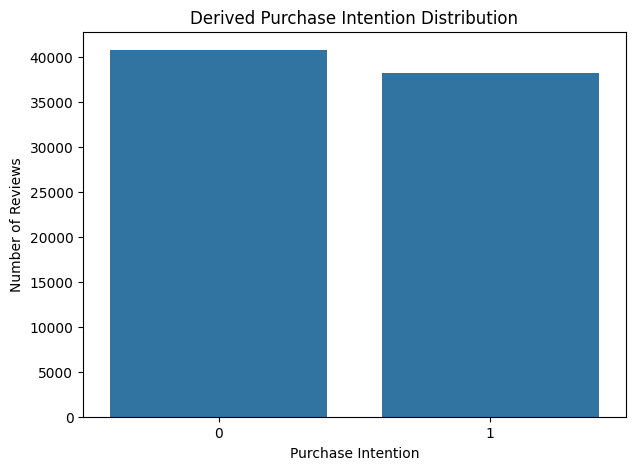

In [10]:
class_table = df["purchase_intention"].value_counts().rename_axis(
    "Purchase Intention"
).reset_index(name="Reviews")

class_table["Percentage"] = (
    class_table["Reviews"] / len(df) * 100
).round(2)

display(class_table)

plt.figure(figsize=(7,5))
sns.countplot(data=df, x="purchase_intention")
plt.title("Derived Purchase Intention Distribution")
plt.xlabel("Purchase Intention")
plt.ylabel("Number of Reviews")
plt.show()

## 11. Rating distribution

,Rating,Reviews,Percentage
0,1.0,14675,18.59
1,2.0,7566,9.59
2,3.0,8719,11.05
3,4.0,17717,22.45
4,5.0,30253,38.33


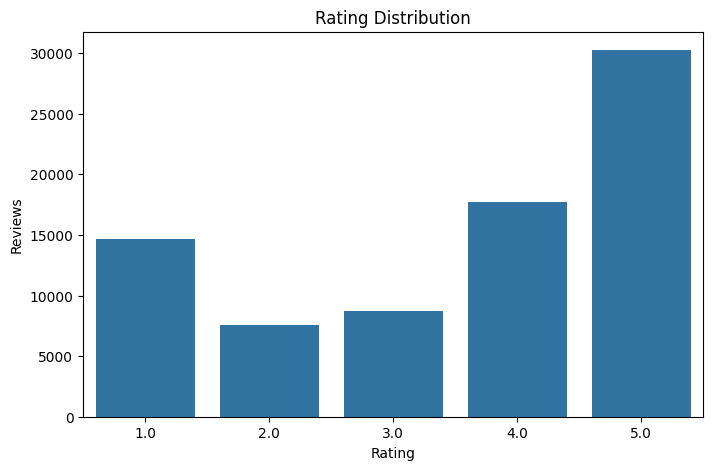

In [11]:
rating_table = df["score"].value_counts().sort_index().reset_index()
rating_table.columns = ["Rating", "Reviews"]
rating_table["Percentage"] = (rating_table["Reviews"] / len(df) * 100).round(2)

display(rating_table)

plt.figure(figsize=(8,5))
sns.countplot(data=df, x="score", order=sorted(df["score"].dropna().unique()))
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Reviews")
plt.show()

## 12. Text preprocessing

In [12]:
STOPWORDS = set(stopwords.words("english"))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [w for w in text.split() if w not in STOPWORDS and len(w) > 2]
    return " ".join(tokens)

df["clean_text"] = (
    df["summary"] + " " + df["review_text"]
).apply(clean_text)

display(df[["review_text", "clean_text"]].head())

,review_text,clean_text
0,"First of all, the company took my money and se...",buy first company took money sent email tellin...
1,Great product- tried others and this is a ten ...,mobile action bluetooth mobile phone tool soft...
2,works real good....a little hard to set up...w...,good works real good little hard set web part ...
3,The price was right for this cable ($11.95+$4....,instructions included price right cable compar...
4,this is NOT a DATA CABLE this is only a USB ch...,data cable data cable usb charger dont buy


## 13. Prepare ML dataset

In [13]:
model_df = df[
    (df["clean_text"].str.len() > 10)
].copy()

# Reproducible sample to keep Colab memory/time manageable.
MAX_ROWS = 50000

if len(model_df) > MAX_ROWS:
    model_df = model_df.sample(MAX_ROWS, random_state=42)

X = model_df["clean_text"]
y = model_df["purchase_intention"]

print("Model rows:", len(model_df))
print("Class distribution:")
display(y.value_counts())

Model rows: 50000
Class distribution:


,count
purchase_intention,
0,25817
1,24183


## 14. Train-test split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40000
Testing samples: 10000


## 15. TF-IDF feature extraction

In [15]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (40000, 10000)
Testing TF-IDF shape: (10000, 10000)


## 16. Logistic Regression

In [16]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)
lr_prob = lr_model.predict_proba(X_test_tfidf)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, lr_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, lr_prob), 4))
print()
print(classification_report(y_test, lr_pred))

Accuracy: 0.88
ROC-AUC: 0.9495

              precision    recall  f1-score   support

           0       0.88      0.89      0.88      5163
           1       0.88      0.87      0.88      4837

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



## 17. Random Forest

In [17]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

rf_pred = rf_model.predict(X_test_tfidf)
rf_prob = rf_model.predict_proba(X_test_tfidf)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print()
print(classification_report(y_test, rf_pred))

Accuracy: 0.8801
ROC-AUC: 0.9494

              precision    recall  f1-score   support

           0       0.90      0.87      0.88      5163
           1       0.86      0.90      0.88      4837

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



## 18. Model comparison

,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.8800,0.9495
1,Random Forest,0.8801,0.9494


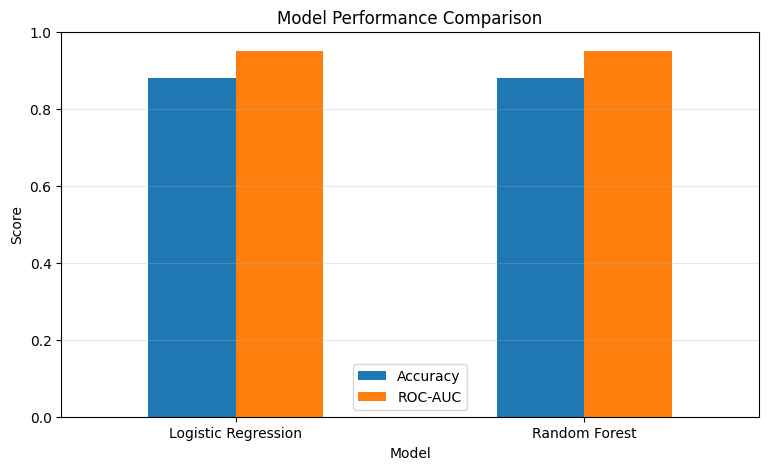

In [18]:
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_pred),
        "ROC-AUC": roc_auc_score(y_test, lr_prob)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "ROC-AUC": roc_auc_score(y_test, rf_prob)
    }
])

results[["Accuracy", "ROC-AUC"]] = results[["Accuracy", "ROC-AUC"]].round(4)

display(results)

results.set_index("Model").plot(
    kind="bar",
    figsize=(9,5)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 19. Confusion matrix

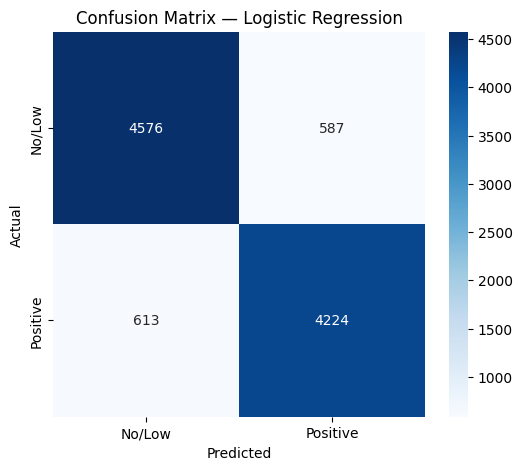

In [19]:
cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No/Low", "Positive"],
    yticklabels=["No/Low", "Positive"]
)
plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 20. Most influential words

In [20]:
feature_names = np.array(tfidf.get_feature_names_out())
coefficients = lr_model.coef_[0]

top_positive = np.argsort(coefficients)[-20:][::-1]
top_negative = np.argsort(coefficients)[:20]

positive_words = pd.DataFrame({
    "Word/Phrase": feature_names[top_positive],
    "Coefficient": coefficients[top_positive]
})

negative_words = pd.DataFrame({
    "Word/Phrase": feature_names[top_negative],
    "Coefficient": coefficients[top_negative]
})

print("Positive indicators")
display(positive_words)

print("Negative indicators")
display(negative_words)

Positive indicators


,Word/Phrase,Coefficient
0,great,24.365633
1,excellent,14.881736
2,love,13.288519
3,perfect,12.788296
4,perfectly,10.892097
5,happy,9.912967
6,satisfied,8.420323
7,good product,8.412000
8,bought,7.746940
9,recommend,6.980568


Negative indicators


,Word/Phrase,Coefficient
0,poor,-6.393014
1,disappointed,-5.286609
2,worst,-5.269062
3,terrible,-4.889392
4,horrible,-4.884594
5,useless,-4.743414
6,return,-4.600038
7,returned,-4.592175
8,bad,-3.506067
9,waste,-3.397253


## 21. Product-level analysis

In [21]:
product_summary = df.groupby("product_id").agg(
    Reviews=("product_id", "size"),
    Average_Rating=("score", "mean"),
    Purchase_Intention_Rate=("purchase_intention", "mean"),
    Average_Review_Length=("review_length", "mean")
).reset_index()

product_summary["Average_Rating"] = product_summary["Average_Rating"].round(2)
product_summary["Purchase_Intention_Rate"] = (
    product_summary["Purchase_Intention_Rate"] * 100
).round(2)
product_summary["Average_Review_Length"] = (
    product_summary["Average_Review_Length"].round(1)
)

display(
    product_summary.sort_values(
        ["Reviews", "Purchase_Intention_Rate"],
        ascending=[False, False]
    ).head(20)
)

,product_id,Reviews,Average_Rating,Purchase_Intention_Rate,Average_Review_Length
2216,B0009B0IX4,3443,4.16,66.63,94.2
2040,B0007WWAGI,984,3.35,43.70,84.8
4074,B000GAO9T2,848,3.81,59.32,90.3
3058,B000CQXHOS,628,3.53,48.25,108.3
7392,B000RUPEOA,623,3.20,42.38,116.1
6406,B000NKCO5Q,558,2.97,39.25,130.2
568,B00006JPFU,528,3.43,49.43,79.4
7244,B000Q6R4MK,515,4.06,66.02,94.1
5347,B000JKKE5M,509,3.75,55.80,93.4
724,B0000AGRYX,501,3.19,40.32,153.7


## 22. Yearly trend

,Year,Reviews,Purchase_Intention_Rate,Average_Rating
0,1999,4,50.00,3.25
1,2000,242,65.29,4.04
2,2001,1111,50.50,3.66
3,2002,739,46.28,3.50
4,2003,1448,52.69,3.63
5,2004,3057,49.95,3.46
6,2005,6502,44.02,3.28
7,2006,9987,45.91,3.39
8,2007,19193,49.52,3.57
9,2008,13418,49.78,3.58


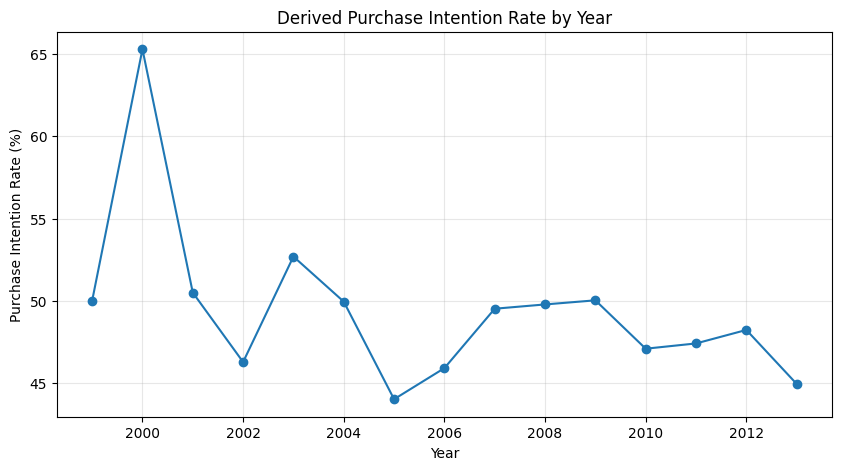

In [22]:
time_df = df.dropna(subset=["review_date"]).copy()
time_df["Year"] = time_df["review_date"].dt.year

yearly = time_df.groupby("Year").agg(
    Reviews=("review_text", "size"),
    Purchase_Intention_Rate=("purchase_intention", "mean"),
    Average_Rating=("score", "mean")
).reset_index()

yearly["Purchase_Intention_Rate"] = (
    yearly["Purchase_Intention_Rate"] * 100
).round(2)
yearly["Average_Rating"] = yearly["Average_Rating"].round(2)

display(yearly)

plt.figure(figsize=(10,5))
plt.plot(
    yearly["Year"],
    yearly["Purchase_Intention_Rate"],
    marker="o"
)
plt.title("Derived Purchase Intention Rate by Year")
plt.xlabel("Year")
plt.ylabel("Purchase Intention Rate (%)")
plt.grid(True, alpha=0.3)
plt.show()

## 23. Save outputs

In [23]:
OUTPUT_DIR = "amazon_cellphone_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df.to_csv(
    os.path.join(OUTPUT_DIR, "cell_phones_accessories_processed.csv"),
    index=False
)

results.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

yearly.to_csv(
    os.path.join(OUTPUT_DIR, "yearly_purchase_intention.csv"),
    index=False
)

product_summary.to_csv(
    os.path.join(OUTPUT_DIR, "product_summary.csv"),
    index=False
)

print("Saved to:", OUTPUT_DIR)

Saved to: amazon_cellphone_outputs


## 24. Research reporting note

For the journal manuscript, clearly state that **purchase intention is a derived proxy** because the SNAP review dataset does not directly record whether a reviewer subsequently purchased a product.

Report:
- Dataset and category
- Number of reviews
- Preprocessing
- Feature engineering
- Proxy-label construction
- Class distribution
- Train/test split
- TF-IDF settings
- ML algorithms
- Accuracy, precision, recall, F1 and ROC-AUC
- Limitations

**Source:** Stanford SNAP Amazon Reviews. citeturn0search0
